# 07 · Ranking: deeper tests

Notebook 04 ranked the top 3 suitable crops by **expected gross revenue** = suitability × yield × price, and fruit
won even when it was a poor fit (papaya at 24% over chickpea at 62% in Vidisha). What does the literature use instead?

- **Net return, not gross revenue.** Crop-choice and farm-planning studies rank by profit: revenue minus cost
  (CACP cost concepts A2+FL, C2 for India; TOPSIS and portfolio studies use profit, cost and return on investment).
- **Perennials need annualising.** Orchards earn nothing for years: a mango NPV study in Rewa (MP) had costs only in
  years 1–6, first income in year 7. Comparing an orchard's mature-year revenue with one season of chickpea is unfair.
- **Risk matters.** Studies use mean/SD or coefficient of variation of returns, or portfolio methods.

New data: **CACP cost of cultivation** (DES, via India Data Portal), state × crop × year 1996–2022, Rs/ha.
It covers 9 of our crops (rice, maize, chickpea, pigeonpeas, mungbean, blackgram, lentil, cotton, jute), **no fruit**.
Costs are from older years than our prices, so we use the **cost share**: cost ÷ gross value in CACP's own data, and
apply it to our current revenue (assumes costs moved with prices).

Two tests:
1. **Revealed preference.** Farmers' area choices bake in cost, risk and markets. Across real districts (DES), does
   gross revenue or net return agree better with what farmers actually grow most?
2. **Agronomy vs economics trade-off.** On Kaggle out-of-fold predictions (where the true suitable crop is known),
   how often does each ranking rule put a crop that isn't the right one first, and how often a fruit?

In [1]:
import sys
sys.path.insert(0, '../project')
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import data

SEED = 42
RAW, RESULTS, FIGS = Path('../data/raw'), Path('../research/results'), Path('../research/figures')
pd.set_option('display.width', 220)
FRUIT = ['apple', 'banana', 'coconut', 'coffee', 'grapes', 'mango', 'muskmelon', 'orange', 'papaya', 'pomegranate', 'watermelon']

## 1. CACP cost shares

In [2]:
CACP = {'Paddy': 'rice', 'Maize': 'maize', 'Gram': 'chickpea', 'Tur (Arhar)': 'pigeonpeas', 'Moong': 'mungbean',
        'Urad': 'blackgram', 'Lentil': 'lentil', 'Masur': 'lentil', 'Cotton': 'cotton', 'Jute': 'jute'}
cost = pd.read_csv(RAW / 'cost' / 'cost-of-cultivation.csv')
cost = cost[cost.crop_name.isin(CACP)].assign(crop=lambda d: d.crop_name.map(CACP))
cost['gvo'] = cost.main_product_value + cost.by_product_value.fillna(0)
cost['a2fl_share'] = cost.cul_cost_a2fl / cost.gvo
cost['c2_share'] = cost.cul_cost_c2 / cost.gvo
recent = cost[cost.year >= '2017-18']  # last 5 survey years
share_state = recent.groupby(['crop', 'state_name'])[['a2fl_share', 'c2_share']].median()
share_crop = recent.groupby('crop')[['a2fl_share', 'c2_share']].median()
share_crop.round(2).sort_values('a2fl_share')

,a2fl_share,c2_share
crop,,
lentil,0.50,0.83
jute,0.55,0.82
chickpea,0.58,0.85
pigeonpeas,0.62,0.94
rice,0.70,0.98
maize,0.73,1.04
cotton,0.73,0.97
blackgram,0.76,1.10
mungbean,0.76,1.04


Paid-out costs plus family labour (A2+FL) eat 50–76% of gross value; including land rent and interest (C2),
many crops barely break even. So costs are big and they differ by crop: gross revenue alone can mislead.

## 2. Revealed preference: which score matches what districts grow?

For each district: crops with a DES yield reported 2018-19 or later, a state price, and (for net scores) a CACP cost share.
Price = mean state mandi price Jan 2021 – Dec 2023 (the same years as the DES yields). Score per crop, then:
- **Spearman ρ** between score and area within the district (averaged over districts with ≥ 3 crops),
- **top-1 match**: the highest-scoring crop is the one with the most area.

In [3]:
yields = data.district_yield()
yields = yields[yields.last_year >= '2018-2019']
prices = data.mandi_prices()
p_state = prices[prices.month < '2024-01-01'].groupby(['crop', 'state']).price.mean().rename('price')
d = yields.merge(p_state, left_on=['crop', 'state_name'], right_index=True)
d['gross'] = d.yield_t_ha * 10 * d.price
d = d.join(share_state, on=['crop', 'state_name'])
for s in ['a2fl_share', 'c2_share']:  # states CACP doesn't survey get the crop's national median
    d[s] = d[s].fillna(d.crop.map(share_crop[s]))
d['net_a2fl'] = d.gross * (1 - d.a2fl_share)
d['net_c2'] = d.gross * (1 - d.c2_share)
print(len(d), 'crop-district rows,', d.district_code.nunique(), 'districts,', d.crop.nunique(), 'crops')


def agreement(df, score):
    rows = []
    for _, g in df.dropna(subset=[score]).groupby('district_code'):
        if len(g) < 3:
            continue
        rho = stats.spearmanr(g[score], g.area_ha).statistic
        rows.append({'rho': rho, 'top1': g.loc[g[score].idxmax(), 'crop'] == g.loc[g.area_ha.idxmax(), 'crop']})
    r = pd.DataFrame(rows)
    return pd.Series({'districts': len(r), 'mean Spearman ρ': r.rho.mean(), 'top-1 match %': r.top1.mean() * 100})


field = d[d.crop.isin(share_crop.index)]
rng = np.random.default_rng(SEED)
rp = pd.DataFrame({
    'gross revenue, all crops': agreement(d, 'gross'),
    'gross revenue, field crops': agreement(field, 'gross'),
    'net over A2+FL, field crops': agreement(field, 'net_a2fl'),
    'net over C2, field crops': agreement(field, 'net_c2'),
    'yield only, field crops': agreement(field, 'yield_t_ha'),
    'random score, field crops': agreement(field.assign(r=rng.random(len(field))), 'r'),
}).T.round(3)
rp

4094 crop-district rows, 625 districts, 13 crops


,districts,mean Spearman ρ,top-1 match %
"gross revenue, all crops",586.0,0.059,13.652
"gross revenue, field crops",571.0,0.139,17.338
"net over A2+FL, field crops",571.0,0.043,14.011
"net over C2, field crops",571.0,0.075,18.739
"yield only, field crops",571.0,0.371,40.455
"random score, field crops",571.0,-0.019,15.061


In [4]:
top_gross = d.loc[d.groupby('district_code').gross.idxmax()].crop.value_counts(normalize=True).mul(100).round(1)
top_area = d.loc[d.groupby('district_code').area_ha.idxmax()].crop.value_counts(normalize=True).mul(100).round(1)
pd.DataFrame({'% districts where #1 by gross revenue': top_gross, '% districts where #1 by area': top_area}).fillna(0).sort_values(
    '% districts where #1 by gross revenue', ascending=False).head(12)

,% districts where #1 by gross revenue,% districts where #1 by area
crop,,
banana,40.8,0.3
cotton,17.4,9.3
pigeonpeas,14.6,0.6
rice,7.5,66.2
coconut,5.0,4.3
maize,4.6,8.8
chickpea,4.3,6.4
jute,2.6,0.0
blackgram,2.4,2.2


## 3. Agronomy vs economics: ranking rules on Kaggle

Out-of-fold suitability from the app model (Random Forest, no humidity), 5-fold, so the true crop is known for every row.
Economics per crop: India-median district yield × All-India mean forecast price. Net = gross × (1 − A2+FL share);
crops without CACP cost get the median field-crop share, **an assumption that flatters fruit** (orchards also carry
establishment costs and years without income).

Rules, applied to the top 3 crops with suitability ≥ 5%:
- **suitability**: order by suitability (what the model alone says).
- **p × gross** (notebook 04), **p × net**.
- **net among near-ties**: order by net return, but only among crops with suitability ≥ τ × the top crop's; the rest follow in suitability order. τ = 0.5 and 0.8.

In [5]:
crops = data.kaggle_crops()
FEATS = ['N', 'P', 'K', 'temperature', 'ph', 'rainfall']
classes = sorted(crops.label.unique())
y = crops.label.map({c: i for i, c in enumerate(classes)}).values
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
P = cross_val_predict(rf, crops[FEATS], y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')

fc = pd.read_csv(Path('../data/processed/price_forecast.csv'))
econ = pd.DataFrame({
    'yield_t_ha': data.district_yield().groupby('crop').yield_t_ha.median(),
    'price': fc[fc.state == 'All India'].groupby('crop').price.mean(),
}).reindex(classes)
econ['gross'] = econ.yield_t_ha * 10 * econ.price
econ['a2fl_share'] = share_crop.a2fl_share.reindex(classes).fillna(share_crop.a2fl_share.median())
econ['net'] = econ.gross * (1 - econ.a2fl_share)
econ.round(2)

,yield_t_ha,price,gross,a2fl_share,net
crop,,,,,
apple,NaN,10576.33,NaN,0.70,NaN
banana,38.80,3569.75,1385063.00,0.70,415873.76
blackgram,0.65,6650.83,43460.75,0.76,10244.13
chickpea,1.04,5496.83,56927.13,0.58,24119.72
coconut,5.95,6647.33,395305.85,0.70,118693.03
coffee,0.73,21358.33,155936.54,0.70,46820.91
cotton,0.98,7328.67,71884.91,0.73,19417.34
grapes,22.94,9407.33,2158491.82,0.70,648100.56
jute,1.44,8879.17,127860.00,0.55,57024.00


In [6]:
def rank_rule(p, rule, tau=None):
    top = np.argsort(-p)[:3]
    top = [c for c in top if p[c] >= 0.05] or [top[0]]
    g = econ.gross.values; n = econ.net.values
    key = {
        'suitability': lambda c: p[c],
        'p × gross': lambda c: np.nan_to_num(p[c] * g[c], nan=-1),
        'p × net': lambda c: np.nan_to_num(p[c] * n[c], nan=-1),
    }
    if rule in key:
        return sorted(top, key=key[rule], reverse=True)
    near = [c for c in top if p[c] >= tau * p[top[0]]]
    rest = [c for c in top if c not in near]
    return sorted(near, key=lambda c: np.nan_to_num(n[c], nan=-1), reverse=True) + rest


rules = [('suitability', None), ('p × gross', None), ('p × net', None), ('net among near-ties', 0.5), ('net among near-ties', 0.8)]
fruit_idx = {classes.index(f) for f in FRUIT}
rows = []
for rule, tau in rules:
    firsts = np.array([rank_rule(P[i], rule, tau)[0] for i in range(len(P))])
    name = rule + (f' (τ={tau})' if tau else '')
    rows.append({'rule': name,
                 '#1 is the true crop %': (firsts == y).mean() * 100,
                 '#1 is a fruit %': np.isin(firsts, list(fruit_idx)).mean() * 100,
                 '#1 is a fruit the row is NOT %': (np.isin(firsts, list(fruit_idx)) & (firsts != y)).mean() * 100,
                 'mean net of #1 (Rs/ha, if it grows)': np.nanmean(econ.net.values[firsts])})
rules_tab = pd.DataFrame(rows).set_index('rule').round(1)
rules_tab

,#1 is the true crop %,#1 is a fruit %,#1 is a fruit the row is NOT %,"mean net of #1 (Rs/ha, if it grows)"
rule,,,,
suitability,98.4,50.0,0.0,130498.7
p × gross,94.5,50.3,0.9,130254.5
p × net,94.2,50.2,0.8,130448.9
net among near-ties (τ=0.5),98.2,50.0,0.0,130526.6
net among near-ties (τ=0.8),98.5,50.0,0.0,130570.4


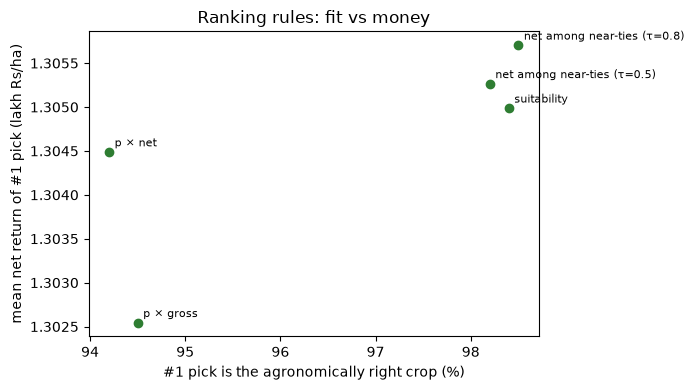

In [7]:
rp.to_csv(RESULTS / '2026-11-03_ranking_revealed_preference.csv')
rules_tab.to_csv(RESULTS / '2026-11-03_ranking_rules.csv')
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(rules_tab['#1 is the true crop %'], rules_tab['mean net of #1 (Rs/ha, if it grows)'] / 1e5, color='#2e7d32')
for name, r in rules_tab.iterrows():
    ax.annotate(name, (r['#1 is the true crop %'], r['mean net of #1 (Rs/ha, if it grows)'] / 1e5), fontsize=8,
                xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('#1 pick is the agronomically right crop (%)')
ax.set_ylabel('mean net return of #1 pick (lakh Rs/ha)')
ax.set_title('Ranking rules: fit vs money')
plt.tight_layout()
plt.savefig(FIGS / 'ranking_rules_tradeoff.png', dpi=150)